In [1]:
%matplotlib ipympl

import seaborn as sns
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import ipywidgets as widgets
from IPython.display import display
import random, math
from scipy.stats import norm
import scipy


In [213]:
def fetch_option_data(ticker, start_date:str, end_date:str, start_strike:float, end_strike:float):
    asset = yf.Ticker(ticker)
    start_date = pd.to_datetime(start_date)
    end_date = pd.to_datetime(end_date)
    current_price = asset.fast_info.last_price

    expirations = asset.options


    options = []

    for exp in expirations:

        
        opt_chain = asset.option_chain(exp)

        calls = opt_chain.calls.copy()
        puts = opt_chain.puts.copy()

        calls["optionType"] = "call"
        puts["optionType"] = "put"

        # Convert to datetime for dataframe
        expiration = pd.to_datetime(exp)

        calls["expiration"] = expiration
        puts["expiration"] = expiration


        calls["daysToExpiration"] = (
            expiration - pd.Timestamp.now()
        ).days

        puts["daysToExpiration"] = (
            expiration - pd.Timestamp.now()
        ).days

        options.append(calls)
        options.append(puts)

    options = pd.concat(options, ignore_index=True)

    options["moneyness"] = options["strike"] / current_price
    options["logMoneyness"] = np.log(options['moneyness'])

    options["midPrice"] = (options["bid"] + options["ask"]) / 2

    options = options[
        (options["strike"] > start_strike) & 
        (options["strike"] < end_strike) & 
        (options["expiration"] > start_date ) & 
        (options["expiration"] < end_date ) & 
        (options["bid"] > 0) & 
        (options['midPrice']) != 0
        # AND ANY OTHER CONDITIONS / BOUNDS YOU WANT HERE
        
    ]

    return options

In [214]:
ticker = "GOOG"
assset = yf.Ticker(ticker)
current_asset_price = asset.fast_info.last_price
# Fetch and visualize the volatility cube for SPY
options_data = fetch_option_data(ticker, start_date="2026-10-10", end_date="2027-01-01", start_strike=100, end_strike=4000)
options_data = options_data.dropna()


In [215]:
calls_data = options_data[options_data['optionType']=='call']

In [216]:
calls_data

,contractSymbol,lastTradeDate,strike,lastPrice,bid,ask,change,percentChange,volume,openInterest,impliedVolatility,inTheMoney,contractSize,currency,optionType,expiration,daysToExpiration,moneyness,logMoneyness,midPrice
124,GOOG261016C00155000,2026-10-09 19:26:31+00:00,155.0,193.20,191.10,195.10,13.399994,7.452722,20.0,349.0,2.312504,True,REGULAR,USD,call,2026-10-16,6,0.445582,-0.808375,193.100
125,GOOG261016C00160000,2026-10-09 19:34:53+00:00,160.0,188.25,186.70,190.10,3.110001,1.679810,58.0,60.0,2.486332,True,REGULAR,USD,call,2026-10-16,6,0.459955,-0.776626,188.400
126,GOOG261016C00165000,2026-10-09 19:37:49+00:00,165.0,183.13,181.40,185.10,-0.019989,-0.010914,2.0,3.0,2.287114,True,REGULAR,USD,call,2026-10-16,6,0.474329,-0.745855,183.250
127,GOOG261016C00170000,2026-10-09 14:24:18+00:00,170.0,179.34,176.40,180.00,14.389999,8.723856,22.0,37.0,2.162114,True,REGULAR,USD,call,2026-10-16,6,0.488702,-0.716002,178.200
128,GOOG261016C00175000,2026-09-16 19:24:36+00:00,175.0,172.55,171.10,174.90,9.000000,5.502904,1.0,262.0,1.863282,True,REGULAR,USD,call,2026-10-16,6,0.503076,-0.687014,173.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
829,GOOG261218C00505000,2026-09-30 17:34:37+00:00,505.0,0.54,0.07,0.75,0.000000,0.000000,5.0,5.0,0.431158,False,REGULAR,USD,call,2026-12-18,69,1.451734,0.372758,0.410
830,GOOG261218C00520000,2026-10-08 15:32:10+00:00,520.0,0.36,0.06,0.70,0.000000,0.000000,1.0,684.0,0.453375,False,REGULAR,USD,call,2026-12-18,69,1.494854,0.402029,0.380
831,GOOG261218C00540000,2026-10-07 14:37:28+00:00,540.0,0.17,0.17,0.44,0.000000,0.000000,2.0,257.0,0.455816,False,REGULAR,USD,call,2026-12-18,69,1.552349,0.439769,0.305
832,GOOG261218C00560000,2026-10-08 15:34:58+00:00,560.0,0.16,0.02,0.48,0.000000,0.000000,15.0,996.0,0.492925,False,REGULAR,USD,call,2026-12-18,69,1.609843,0.476137,0.250


In [39]:
# Generate the volatility surface
def plot_volatility_surface(data):
    # Filter relevant columns and pivot for 3D plotting
    c = 'strike'
    surface_data = data[['daysToExpiration', c, 'impliedVolatility']].dropna()
    surface_data[c] = np.round(surface_data[c],5)
    surface = surface_data.pivot_table(values='impliedVolatility', index=c, columns='daysToExpiration')
    
    # Prepare grid for 3D plot
    X, Y = np.meshgrid(surface.columns.values, surface.index.values)
    Z = surface.values
    
    # Plot the 3D surface
    fig = plt.figure(figsize=(5,5))
    ax = fig.add_subplot(111, projection='3d')
    ax.plot_surface(X, Y, Z, cmap='viridis') # scatter or plot_surface

    
    ax.set_xlabel('Days to Expiration')
    ax.set_ylabel(c)
    ax.set_zlabel('Implied Volatility')
    ax.set_title('Volatility Surface')
    plt.show()


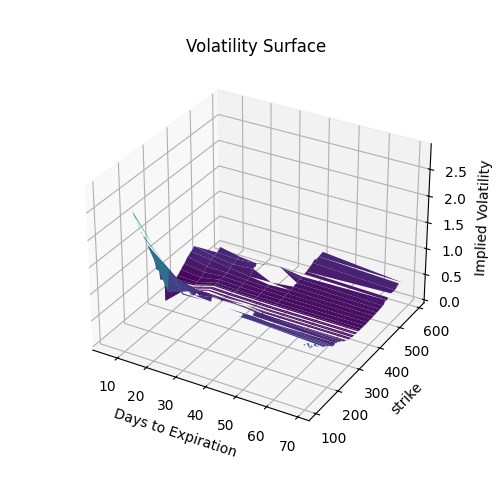

In [40]:
plot_volatility_surface(calls_data)

In [48]:
def plot_iv_strike(data, iv_col="impliedVolatility"):
    avg = data.groupby("strike")[iv_col].mean().sort_index()

    plt.figure()
    plt.plot(avg.index, avg.values, marker="o", markersize=3, linewidth=1)
    plt.axvline(current_asset_price, color="red", linestyle="--", label="current asset price")
    plt.legend()
    plt.title("Average IV by strike")
    plt.xlabel("strike price")
    plt.ylabel("average implied volatility")
    plt.show()

def plot_iv_tte(data):
    plt.figure()
    plt.scatter(data["daysToExpiration"], data["impliedVolatility"], s=5)
    plt.title("Expiration vs IV")
    plt.ylabel("implied volatility")
    plt.xlabel("time to expiration")
    plt.show()

def plot_iv_moneyness(data):
    plt.figure()
    plt.scatter(data["moneyness"], data["impliedVolatility"], s=5)
    plt.title("")
    plt.ylabel("implied volatility")
    plt.xlabel("logMoneyness")
    plt.show()

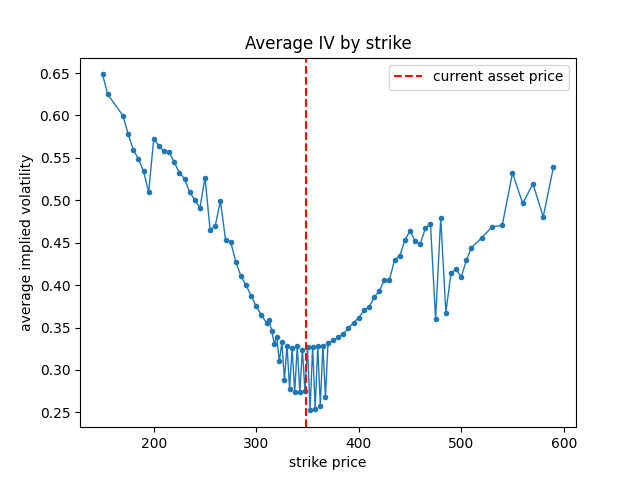

In [49]:
otm = options_data[
    ((options_data["optionType"] == "put")  & (options_data["strike"] < current_asset_price)) |
    ((options_data["optionType"] == "call") & (options_data["strike"] >= current_asset_price))
]
plot_iv_strike(otm)

In [50]:
class StochasticProcess:
    def __init__(self, drift, volatility, dt, initial_asset_price):
        self.drift = drift
        self.volatility = volatility
        self.dt = dt
        self.asset_prices = [initial_asset_price]
        self.current_asset_price = initial_asset_price


    def time_step(self):
        z = np.random.normal()

        self.current_asset_price *= np.exp(
            (self.drift - 0.5 * self.volatility**2) * self.dt
            + self.volatility * np.sqrt(self.dt) * z
        )

        self.asset_prices.append(self.current_asset_price)


In [217]:
def black_scholes_call(S, K, T, r, q, sigma):
    d1 = (
        np.log(S / K)
        + (r - q + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    call_price = (
        S * np.exp(-q * T) * norm.cdf(d1)
        - K * np.exp(-r * T) * norm.cdf(d2)
    )

    return call_price

In [218]:
calls_data.sample()

,contractSymbol,lastTradeDate,strike,lastPrice,bid,ask,change,percentChange,volume,openInterest,impliedVolatility,inTheMoney,contractSize,currency,optionType,expiration,daysToExpiration,moneyness,logMoneyness,midPrice
425,GOOG261030C00370000,2026-10-09 19:54:06+00:00,370.0,5.2,4.9,5.3,0.3,6.122443,250.0,1269.0,0.387091,False,REGULAR,USD,call,2026-10-30,20,1.063646,0.061703,5.1


In [219]:
black_scholes_call(S = current_asset_price, K = 335, T = 27/252, r =0.04, q=0.20, sigma=0.365973)

19.791333590984465

In [220]:
processes = []


def plot_simple_gbm(drift=.2,volatility=.3):
    plt.figure()
    for i in range(0,10):
        process = StochasticProcess(drift=drift,volatility=volatility,dt=1/365,initial_asset_price=100)
        tte = 1
        while(tte - process.dt) > 0:
            process.time_step()
            tte = tte - process.dt
        #processes.append(process)

        plt.plot(process.asset_prices)
        
    plt.xlabel("Time Steps")
    plt.ylabel("Asset Price")
    plt.title("GBM")
    plt.plot(process.asset_prices)
    plt.show()

widgets.interact(
    plot_simple_gbm,
    drift=(-2,2,0.01),
    volatility=(0.0001, 2,0.001),
)

interactive(children=(FloatSlider(value=0.2, description='drift', max=2.0, min=-2.0, step=0.01), FloatSlider(v…

<function __main__.plot_simple_gbm(drift=0.2, volatility=0.3)>

# Black-scholes implied volatility

## $\sigma = min_\sigma(C_{mkt} - C_{BS})^2$

In [224]:
from scipy.optimize import brentq

from scipy.optimize import newton

def implied_volatility(C, S, K, r, T):
    q = 0.01
    
    f = lambda sigma: black_scholes_call(S, K, T, r, q, sigma) - C

    try:
        z = newton(f, x0=0.3)
    except RuntimeError:
        return np.NaN
    return z

In [244]:
c = calls_data.sample().iloc[0]
c

contractSymbol             GOOG261218C00485000
lastTradeDate        2026-10-01 18:57:45+00:00
strike                                   485.0
lastPrice                                 0.59
bid                                        0.4
ask                                       0.53
change                                     0.0
percentChange                              0.0
volume                                     1.0
openInterest                               5.0
impliedVolatility                      0.37171
inTheMoney                               False
contractSize                           REGULAR
currency                                   USD
optionType                                call
expiration                 2026-12-18 00:00:00
daysToExpiration                            69
moneyness                             1.394239
logMoneyness                          0.332349
midPrice                                 0.465
Name: 825, dtype: object

In [245]:
implied_volatility(C =c.midPrice, S = current_asset_price, K= c.strike, r = 0.04, T = c.daysToExpiration/365)

0.3645140378149553

In [227]:

iv_graph_data = calls_data[["midPrice", "strike", "daysToExpiration", "moneyness", "logMoneyness", "optionType"]].copy()

In [228]:
iv_graph_data

,midPrice,strike,daysToExpiration,moneyness,logMoneyness,optionType
124,193.100,155.0,6,0.445582,-0.808375,call
125,188.400,160.0,6,0.459955,-0.776626,call
126,183.250,165.0,6,0.474329,-0.745855,call
127,178.200,170.0,6,0.488702,-0.716002,call
128,173.000,175.0,6,0.503076,-0.687014,call
...,...,...,...,...,...,...
829,0.410,505.0,69,1.451734,0.372758,call
830,0.380,520.0,69,1.494854,0.402029,call
831,0.305,540.0,69,1.552349,0.439769,call
832,0.250,560.0,69,1.609843,0.476137,call


In [231]:
iv_graph_data["BSIV"] = iv_graph_data.apply(lambda row: implied_volatility(C=row['midPrice'], 
                                                                           S=current_asset_price, 
                                                                           K=row['strike'], 
                                                                           r=0.04, 
                                                                           T=row['daysToExpiration']/365 ), axis=1)


C:\Users\vflip\AppData\Local\Temp\ipykernel_19412\3673858939.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  iv_graph_data["BSIV"] = iv_graph_data.apply(lambda row: implied_volatility(C=row['midPrice'],


In [232]:
iv_graph_data = iv_graph_data.dropna()

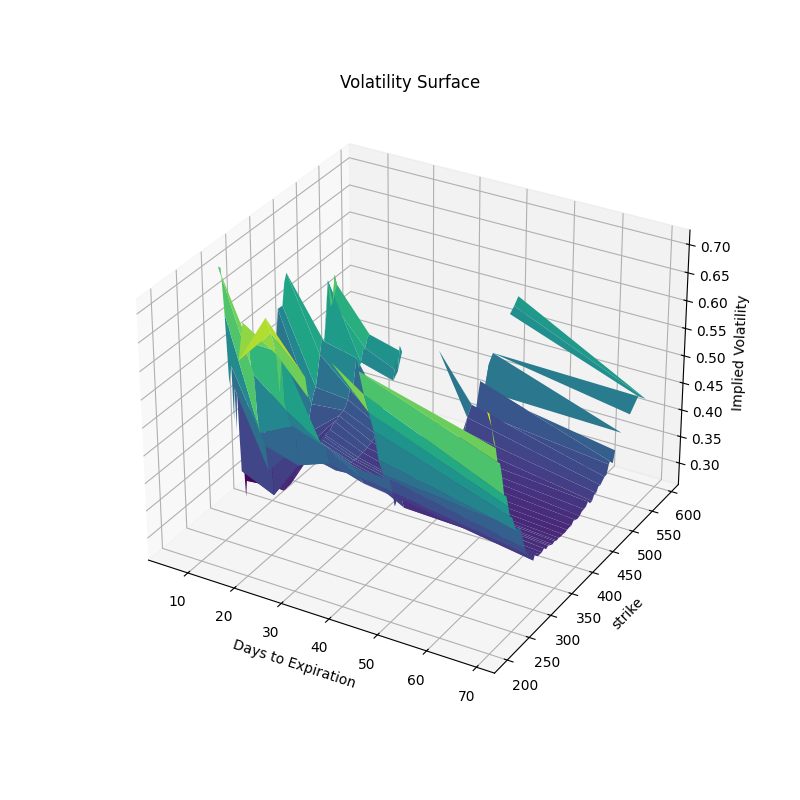

In [233]:
def plot_volatility_surface(data):
    # Filter relevant columns and pivot for 3D plotting
    c = 'strike'
    surface_data = data[['daysToExpiration', c, 'BSIV']].dropna()
    surface_data[c] = np.round(surface_data[c],5)
    surface = surface_data.pivot_table(values='BSIV', index=c, columns='daysToExpiration')
    
    # Prepare grid for 3D plot
    X, Y = np.meshgrid(surface.columns.values, surface.index.values)
    Z = surface.values
    
    # Plot the 3D surface
    fig = plt.figure(figsize=(8,8))
    ax = fig.add_subplot(111, projection='3d')
    ax.plot_surface(X, Y, Z, cmap='viridis') # scatter or plot_surface
    
    ax.set_xlabel('Days to Expiration')
    ax.set_ylabel(c)
    ax.set_zlabel('Implied Volatility')
    ax.set_title('Volatility Surface')
    plt.show()

plot_volatility_surface(iv_graph_data)